# Exemplar Patient Fits - Zhang et al


In [2]:
import os
import re
import sys
import pickle
import numpy as np
import pandas as pd
import scipy as sc
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from lmfit import minimize, Parameters
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (test_progression, TruncateDataframe, ExtractTreatmentFromDf, LoadPatientData, GetPatientIDs,
                     )
from fittingUtils import residual, compute_r_sq, load_fit, generate_fitSummaryDf
from plotUtils import PlotDrug, PlotData, convert_to_rgb_grayscale, redistribute_rgb
from odeModels import LotkaVolterraModel

In [3]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

In [4]:
file_path = os.path.dirname(os.path.abspath("__file__"))

RERUN_FITTING = True

In [5]:
def SimulateFit(fit_params, dataDf, dt=1, solver_kws={}):
    myModel = LotkaVolterraModel()
    myModel.SetParams(**fit_params)
    myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
    # Interpolate to the desired time grid
    t_eval = np.arange(0, myModel.resultsDf.Time.max(), dt)
    trimmedResultsDic = {'Time': t_eval}
    for variable in ['S', 'R', 'TumourSize', 'DrugConcentration']:
        f = sc.interpolate.interp1d(myModel.resultsDf.Time, myModel.resultsDf[variable])
        trimmedResultsDic = {**trimmedResultsDic, variable: f(t_eval)}
    myModel.resultsDf = pd.DataFrame(trimmedResultsDic)
    return myModel

## Patient Datasets

In [6]:
# Overwrite helperS function for this dataA format
def LoadPatientData(patientId, dataDir):
    patientDataDf = pd.read_csv(os.path.join(dataDir, "patient%.3d.csv" % patientId))
    patientDataDf.drop(labels='PSA', axis=1, inplace=True)
    patientDataDf.rename({'Days': 'Time', 'Abi': 'DrugConcentration',
                          'relPSA_Indi': 'PSA'}, axis=1, inplace=True)
    patientDataDf = patientDataDf.sort_values(by="Time")
    return patientDataDf

Loaded Patient IDs: [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1009, 1010, 1011, 1012, 1014, 1015, 1016, 1017, 1018, 1020]


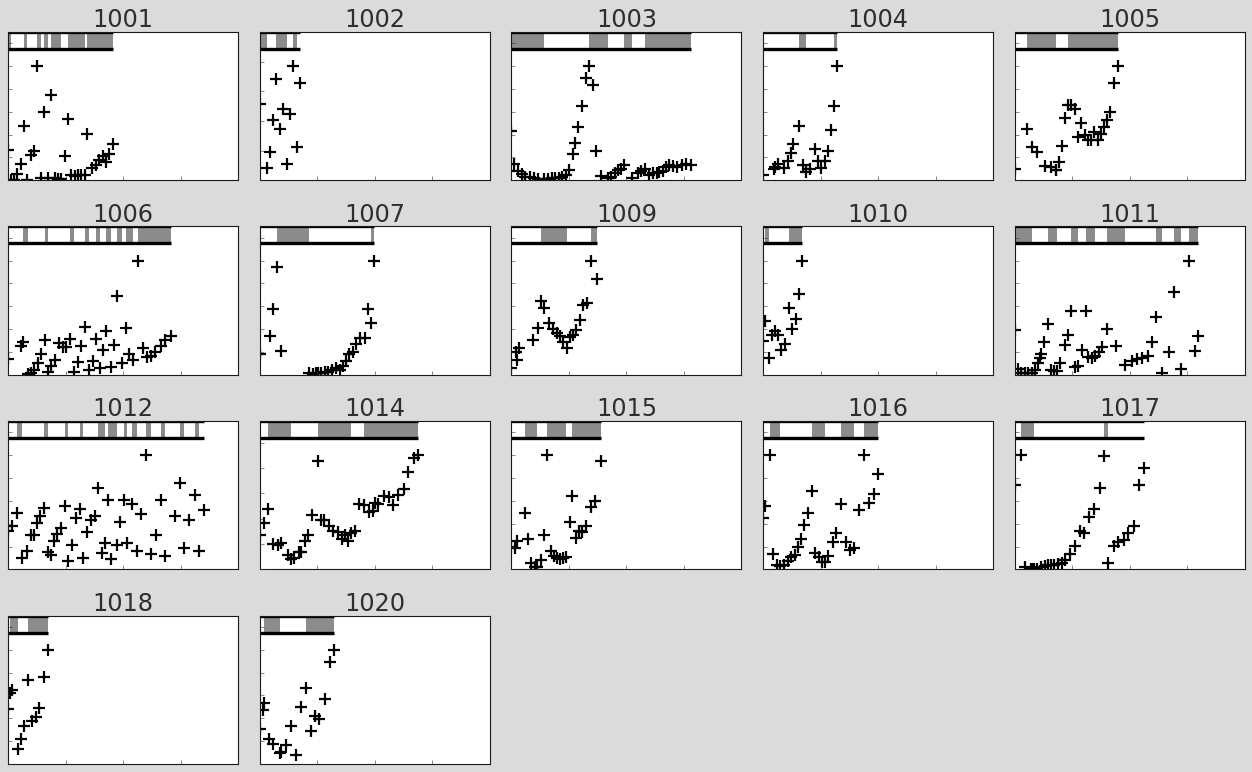

In [7]:
data_path = "../patients/Zhang_et_al/at_patients/data"
patientIds = GetPatientIDs(data_path)
print("Loaded Patient IDs: " + str(patientIds))


plt.rcParams['font.size'] = '18'; n_row=4
fig, axs = plt.subplots(n_row, int((len(patientIds)+(n_row-1))/n_row), figsize=(16, 10))
for i, patientId in enumerate(patientIds):
    dataDf = LoadPatientData(patientId, data_path)
    PlotData(dataDf, axs.flatten()[i], drugBarPosition=max(dataDf.PSA)*1.15,
             drugBarHeight=max(dataDf.PSA)*0.15)
    axs.flatten()[i].set_title(patientId)
    axs.flatten()[i].set_ylim(0, max(dataDf.PSA) * 1.3)
    axs.flatten()[i].set_xticklabels([]); axs.flatten()[i].set_yticklabels([])

for i in range(len(patientIds), axs.size):
    axs.flatten()[i].axis('off')
plt.tight_layout()
# plt.savefig("Zhang_et_al_patients.pdf")


In [8]:
def calculate_no_treatment_periods(patient_data):
    no_treatment_periods = []
    start_time = None
    in_no_treatment = False
    
    for index, row in patient_data.iterrows():
        if row['DrugConcentration'] == 0:
            if not in_no_treatment:
                in_no_treatment = True
                start_time = row['Time']
        else:
            if in_no_treatment:
                no_treatment_periods.append(row['Time'] - start_time)
                in_no_treatment = False
                start_time = None
    
    if in_no_treatment and start_time is not None:
        no_treatment_periods.append(patient_data['Time'].iloc[-1] - start_time)
    
    return no_treatment_periods

def average_no_treatment_periods(patient_data):
    no_treatment_periods = calculate_no_treatment_periods(patient_data)
    if no_treatment_periods:
        return np.mean(no_treatment_periods)
    else:
        return 0

average_no_treatment_durations = {}
for patientId in patientIds:
    dataDf = LoadPatientData(patientId, data_path)
    avg_duration = average_no_treatment_periods(dataDf)
    average_no_treatment_durations[patientId] = int(avg_duration)

print(average_no_treatment_durations)
print(f"Minimum average no treatment duration: {min(average_no_treatment_durations.values())}")
print(f"Maximum average no treatment duration: {max(average_no_treatment_durations.values())}")


{1001: 57, 1002: 56, 1003: 217, 1004: 278, 1005: 107, 1006: 91, 1007: 347, 1009: 234, 1010: 99, 1011: 107, 1012: 93, 1014: 139, 1015: 84, 1016: 140, 1017: 324, 1018: 53, 1020: 132}
Minimum average no treatment duration: 53
Maximum average no treatment duration: 347


#### Patient Data Issues


* Data for Patient 1002 is not normalised. While this analysis de facto normalises all datasets anyway, the data is also not given in ng/mol, and so I believe has been normalised to a valued that is not included in the published dataset. This issue was raised about preliminary dataset, but has not been resolved in published version.

* Unexplained dynamics - most notably the late time `cycles' under constant treatment for 1005 and 1014. I don't believe these are feasibly noise or non-clinical interventions - it is possible that this is a response to a chemotherapy for a secondary cancer, but it is more likely that this is an error in the treatment records.

* Sampling frequency on fast cycling patients - this is a limitation rather than a direct issue, but there are insufficient samples per cycle for fast cycling patients to generate accurate fits for these individuals. 

* There is no evidence of progression (i.e. tumor growth under treatment) for multiple patients (such as 1007 or 1017), meaning we cannot reliably fit resistant dynamics to these patients.

#### Patient Exemplar Selection

Building on the issues we discuss above, we exclude the following patients for the reasons below (some patients may be listed twice):

**Patient does not Progress**: $1002, 1004, 1007, 1009, 1011, 1012, 1017$ 

**Insufficient Sampling Frequency**: $1001, 1002, 1006, 1012$

**Spurious Data Recorded**: $1005^{1}, 1010^{2}, 1014^{1}$

This only leaves us with the following patients: $1003, 1015, 1016, 1018, 1020$.

N.B. We also struggle to fit to the patients where the growth rate increases over the course of treatment ($1006, 1011, 1015, 1016$), but do not exclude patients for this reason.

*[1] Well defined peak & cusp in dataset, apparently under constant treatment. For these patients, I have only excluded the spurious behaviour near the end of treatment, rather than the full treatment history.*

*[2] Consistent decrease in tumor size off treatment. Possible missing treatment cycle in patient records.*


In [9]:
patientsToAnalyseSubset = [1001, 1003, 1005, 1014, 1015, 1016, 1018, 1020] 
out_dir = os.path.join(os.pardir, "patients", "Zhang_et_al", "Selected_Patients")

solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

params.add('n0', min=0.1, max=1., vary=True); 
params.add('fR', min=1e-5, max=0.1, vary=True)
params.add('cost', min=0.1, max=0.5, vary=True)
params.add('turnover', min=0.1, max=1., vary=True)
params.add('K', min=0.5, max=10, vary=True)
params.add('rS', value=0.027, min=0.01, max=0.05, vary=True)

# Fixed/Calculated Parameters
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [10]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseSubset):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

100%|██████████| 8/8 [00:55<00:00,  6.95s/it]


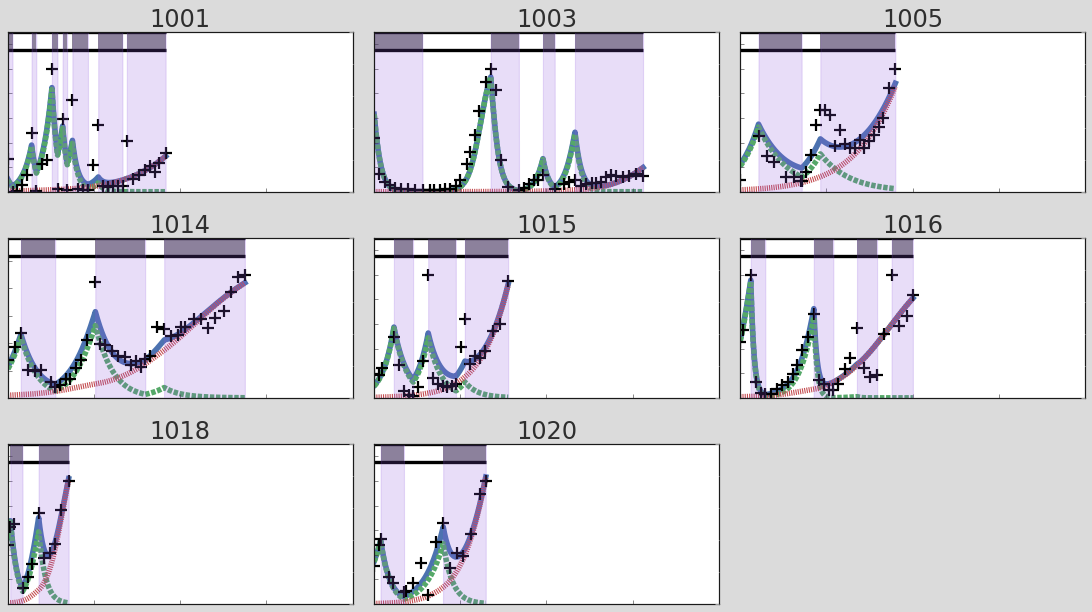

In [11]:
plt.rcParams['font.size'] = '18'; n_row=3
fig, axs = plt.subplots(n_row, int((len(patientsToAnalyseSubset)+(n_row-1))/n_row), figsize=(14, 8))
for i, patientId in enumerate(patientsToAnalyseSubset):
    dataDf = LoadPatientData(patientId, data_path)
    PlotData(dataDf, axs.flatten()[i], drugBarPosition=max(dataDf.PSA)*1.15,
             drugBarHeight=max(dataDf.PSA)*0.15, zorder=10)
    
    if patientId in patientsToAnalyseSubset:
        fitObj,myModel = load_fit(model_name,fitDir=os.path.join(working_dir,"patient%d"%patientId),
                             model=LotkaVolterraModel())
        myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(fitObj.data),**solver_kws)
        myModel.Trim(dt=1)
        myModel.Plot(plotPops=True, ymin=0, linewidth=2, 
                     decoratey2=False, decorateAxes=False, ax=axs.flatten()[i])
        ax=axs.flatten()[i].legend().remove()
    axs.flatten()[i].set_title(patientId)
    axs.flatten()[i].set_ylim(0, max(dataDf.PSA) * 1.3)
    axs.flatten()[i].set_xticklabels([]); axs.flatten()[i].set_yticklabels([])

for i in range(len(patientsToAnalyseSubset), axs.size):
    axs.flatten()[i].axis('off')
plt.tight_layout()

In [16]:
# Store patient parameters in a dataframe
if RERUN_FITTING:
    df_list = []
    for patient_dir in os.listdir(os.path.join(out_dir, model_name)):
        fitSummaryDf = generate_fitSummaryDf(os.path.join(out_dir, model_name, patient_dir))
        fitSummaryDf.insert(0, "PatientId", int(re.findall(r'\d+', patient_dir)[0]))
        df_list.append(fitSummaryDf)
        
    df_subset = pd.concat(df_list, axis=0)
    
    df_subset['TimeInTrial'] = df_subset['PatientId'].apply(lambda x: LoadPatientData(x, data_path).Time.max())
    df_subset = df_subset.sort_values(by="PatientId").reset_index(drop=True)
    df_subset['Cost'] = 1 - df_subset['rR'] / df_subset['rS']
    df_subset['Turnover'] = df_subset['dS'] / df_subset['rS']

    # Test progression
    df_subset['Progression'] = df_subset.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d" % (df_subset.Progression.sum(), len(df_subset)), end='')
    print(f"  ({[x for x in df_subset.PatientId[df_subset.Progression == True]]})")

    df = df_subset[df_subset.Progression == True].copy()
    df.to_csv(os.path.join("patient_fits", "Zhang_full_history.csv"), index=False)

Progression: 7/8  ([1003, 1005, 1014, 1015, 1016, 1018, 1020])


/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_16891/2674635519.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_subset = pd.concat(df_list, axis=0)


## Fit to first cycle only

These parameter values can then subsequently be used for validation later.

In [13]:
patientsToAnalyseList = [1001, 1003, 1005, 1014, 1015, 1016, 1018, 1020] 
out_dir = os.path.join(os.pardir, "patients", "Zhang_et_al", "Selected_Patients_Trunc")


solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

# New
params.add('turnover', min=0.01, max=1., vary=True)
params.add('K', value=3, min=2.5, max=5, vary=True)

# Fixed from historical data/estimates
params.add('fR', value=1e-2, vary=False)
params.add('cost', value=0.01, vary=False)
params.add('rS', value=0.027, vary=False)
params.add('n0', value=0.1, vary=False)  # Will be matched to initial value

# Fixed/Calculated Parameters
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [14]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseList):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index()       
        training_data_df = TruncateDataframe(training_data_df, drug_name='DrugConcentration')
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

 25%|██▌       | 2/8 [00:01<00:03,  1.50it/s]/Users/kitgallagher/Documents/Other/Oxford/Biomarkers Resubmission/Mathematical-Biomarkers/paper_figures/../utils/fittingUtils.py:84: RuntimeWarning: invalid value encountered in scalar divide
  return 1-rss/tss
/Users/kitgallagher/micromamba/envs/general_science/lib/python3.11/site-packages/lmfit/minimizer.py:819: RuntimeWarning: invalid value encountered in sqrt
  par.stderr = float(np.sqrt(self.result.covar[ivar, ivar]))
/Users/kitgallagher/micromamba/envs/general_science/lib/python3.11/site-packages/lmfit/minimizer.py:827: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(self.result.covar[jvar, jvar])))
 62%|██████▎   | 5/8 [00:01<00:00,  4.22it/s]/Users/kitgallagher/micromamba/envs/general_science/lib/python3.11/site-packages/lmfit/minimizer.py:819: RuntimeWarning: invalid value encountered in sqrt
  par.stderr = float(np.sqrt(self.result.covar[ivar, ivar]))
/Users/kitgallagher/micromamba/envs/general_science/lib/python3.11/s

In [15]:
# Store patient parameters in a dataframe
# Target - 7/8 patients, but fitting may be unstable
if RERUN_FITTING:
    trunc_df = pd.DataFrame()
    for patient_dir in os.listdir(os.path.join(out_dir, model_name)):
        fitSummaryDf = generate_fitSummaryDf(os.path.join(out_dir, model_name, patient_dir))
        fitSummaryDf.insert(0, "PatientId",  int(re.findall(r'\d+', patient_dir)[0]))
        trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
        
    trunc_df['TimeInTrial'] = trunc_df['PatientId'].apply(lambda x: \
        LoadPatientData(x, data_path).Time.max())
    trunc_df = trunc_df.sort_values(by="PatientId").reset_index()
    trunc_df = trunc_df[trunc_df['PatientId'].isin(patientIds)]
    trunc_df['Cost'] = 1 - trunc_df['rR'] / trunc_df['rS']
    trunc_df['Turnover'] = trunc_df['dS'] / trunc_df['rS']
    trunc_df['K'] = 6 * trunc_df['n0']

    print(trunc_df[['PatientId', 'n0', 'fR', 'Turnover', 'Cost', 'K', 'rS', 'R0']])

    #Test progression
    trunc_df['Progression'] = trunc_df.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d"%(trunc_df.Progression.sum(), len(trunc_df)), end='')
    print(f"  ({[x for x in trunc_df.PatientId[trunc_df.Progression==True]]})")

    # Save patient params
    trunc_df.to_csv("patient_fits/Zhang_first_cycle.csv", index=False)

   PatientId        n0    fR  Turnover  Cost         K     rS        R0
0       1001  0.264744  0.01  1.000000  0.01  1.588464  0.027  0.002647
1       1003  0.432910  0.01  0.667075  0.01  2.597460  0.027  0.004329
2       1005  0.096340  0.01  0.010000  0.01  0.578040  0.027  0.000963
3       1014  0.274187  0.01  0.611965  0.01  1.645122  0.027  0.002742
4       1015  0.194030  0.01  0.835285  0.01  1.164180  0.027  0.001940
5       1016  0.453670  0.01  0.323081  0.01  2.722020  0.027  0.004537
6       1018  0.477956  0.01  0.010000  0.01  2.867738  0.027  0.004780
7       1020  0.305455  0.01  0.332854  0.01  1.832727  0.027  0.003055
Progression: 6/8  ([1003, 1005, 1014, 1016, 1018, 1020])


/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_16891/2259704849.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_16891/2259704849.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
